# ДЗ 3
### Закирова Е. А.

## иерархическое прогнозирование продаж

в ДЗ 1 и ДЗ 2 я работала с одним товаром 21755. здесь нужно построить
иерархию временных рядов: общий уровень продаж, группы товаров и отдельные
товары, спрогнозировать каждый узел и согласовать прогнозы между собой

согласование значит, что прогноз родительского узла равен сумме прогнозов
дочерних. если посчитать прогнозы узлов независимо, они могут не сходиться
в сумму, поэтому нужен отдельный шаг reconciliation

In [1]:
# %pip install pandas numpy matplotlib statsmodels scikit-learn ucimlrepo

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

## загрузка данных

датасет тот же, что и в ДЗ 1 и ДЗ 2 - Online Retail из UCI.
для загрузки датасета внутри ноутбука нужен интернет

In [3]:
online_retail = fetch_ucirepo(id=352)

df = online_retail.data.original
print("размер датасета:", df.shape)
df.head()

размер датасета: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## подготовка продаж

правила отбора те же, что в ДЗ 1 и ДЗ 2: исключаю отмененные операции,
неположительное количество и неположительную цену. считаю только
положительные платные продажи, возвраты не вычитаю

теперь готовлю продажи не одного товара, а всего датасета:
для иерархии нужны и отдельные товары, и суммы по группам

In [4]:
def prepare_sales(data):
    cancelled = data["InvoiceNo"].astype(str).str.startswith("C")

    sales = data[
        (~cancelled)
        & (data["Quantity"] > 0)
        & (data["UnitPrice"] > 0)
    ].copy()

    sales["InvoiceDate"] = pd.to_datetime(
        sales["InvoiceDate"],
        format="%m/%d/%Y %H:%M"
    )
    sales = sales.sort_values("InvoiceDate")
    return sales.set_index("InvoiceDate")


sales = prepare_sales(df)

print("записей продаж:", len(sales))
print("исключено записей:", len(df) - len(sales))
print("период:", sales.index.min(), "-", sales.index.max())
print("товаров:", sales["StockCode"].nunique())

записей продаж: 530104
исключено записей: 11805
период: 2010-12-01 08:26:00 - 2011-12-09 12:50:00
товаров: 3922


## иерархия

в датасете нет готовых категорий товаров, поэтому структуру иерархии
выбираю сама:

- уровень 0: Всего - продажи всех товаров вместе;
- уровень 1: группы товаров по назначению;
- уровень 2: отдельные товары внутри групп

беру три группы похожих товаров и отбираю в каждой самые продаваемые
по количеству штук:

- Сумки - товары с BAG в названии;
- Формы для выпечки - товары с CAKE CASES в названии;
- Подсвечники - товары с T-LIGHT в названии

крупные товары дают более устойчивые недельные ряды, чем совсем мелкие.
внутри группы товары одного назначения, поэтому групповой прогноз
имеет смысл как отдельная величина, а не только как сумма

все остальные товары объединяю в группу Прочие товары с одним узлом
Остальные товары - суммой продаж всего, что не попало в отбор.
так общий уровень иерархии совпадает со всеми продажами магазина,
а не только с отобранными товарами

каждый товар относится ровно к одной группе, связи родитель-потомок
однозначные. название товара иногда меняется между записями,
для отбора использую StockCode, а Description - только для подписи

отбираю товары по итогам обучающего периода, а не всего датасета:
так будущие продажи не влияют на то, какие узлы попадут в иерархию

In [5]:
horizon = 8
horizons = [1, 4, 8]

group_rules = {
    "Сумки": "BAG",
    "Формы для выпечки": "CAKE CASES",
    "Подсвечники": "T-LIGHT"
}

n_products = {"Сумки": 4, "Формы для выпечки": 4, "Подсвечники": 3}


def select_products(sales, group_rules, n_products, horizon):
    weekly = sales["Quantity"].resample("W-SUN").sum(min_count=1)
    first_day = sales.index.min().normalize()
    last_day = sales.index.max().normalize()
    week_starts = weekly.index - pd.Timedelta(days=6)
    weeks = weekly.index[
        (week_starts >= first_day) & (weekly.index <= last_day)
    ]
    train_cutoff = weeks[:-horizon][-1] + pd.Timedelta(days=1)

    train_sales = sales[sales.index < train_cutoff]
    product_totals = (
        train_sales.groupby("StockCode")["Quantity"].sum()
        .sort_values(ascending=False)
    )
    descriptions = sales.groupby("StockCode")["Description"].first()

    selected = {}
    for group, keyword in group_rules.items():
        candidates = [
            code for code in product_totals.index
            if keyword in str(descriptions[code]).upper()
        ]
        selected[group] = candidates[:n_products[group]]

    all_codes = [code for codes in selected.values() for code in codes]
    assert len(all_codes) == len(set(all_codes)), "товар попал в две группы"

    return selected, descriptions, product_totals, train_cutoff


selected, descriptions, product_totals, train_cutoff = select_products(
    sales, group_rules, n_products, horizon
)

print("отбор товаров по продажам до:", train_cutoff.date())
for group, codes in selected.items():
    print(group)
    for code in codes:
        print(" ", code, descriptions[code], "-", int(product_totals[code]), "шт. (обучение)")

отбор товаров по продажам до: 2011-10-10
Сумки
  85099B JUMBO BAG RED RETROSPOT - 38763 шт. (обучение)
  22386 JUMBO BAG PINK POLKADOT - 17809 шт. (обучение)
  20725 LUNCH BAG RED RETROSPOT - 16120 шт. (обучение)
  85099F JUMBO BAG STRAWBERRY - 15402 шт. (обучение)
Формы для выпечки
  21212 PACK OF 72 RETROSPOT CAKE CASES - 31744 шт. (обучение)
  21977 PACK OF 60 PINK PAISLEY CAKE CASES - 22654 шт. (обучение)
  84991 60 TEATIME FAIRY CAKE CASES - 15260 шт. (обучение)
  21213 PACK OF 72 SKULL CAKE CASES - 13224 шт. (обучение)
Подсвечники
  85123A WHITE HANGING HEART T-LIGHT HOLDER - 30432 шт. (обучение)
  22178 VICTORIAN GLASS HANGING T-LIGHT - 19664 шт. (обучение)
  84755 COLOUR GLASS T-LIGHT HOLDER HANGING - 14961 шт. (обучение)


In [6]:
def build_hierarchy(selected, descriptions):
    bottom_ids = [code for codes in selected.values() for code in codes] + ["Остальные товары"]
    group_ids = list(selected.keys()) + ["Прочие товары"]
    node_ids = ["Всего"] + group_ids + bottom_ids

    children = {group: list(codes) for group, codes in selected.items()}
    children["Прочие товары"] = ["Остальные товары"]
    children["Всего"] = group_ids

    parent_of = {}
    for group, codes in selected.items():
        for code in codes:
            parent_of[code] = group
    parent_of["Остальные товары"] = "Прочие товары"
    for group in group_ids:
        parent_of[group] = "Всего"

    node_info = pd.DataFrame({
        "Узел": node_ids,
        "Уровень": [0] + [1] * len(group_ids) + [2] * len(bottom_ids),
        "Родитель": ["-"] + ["Всего"] * len(group_ids) + [parent_of[node] for node in bottom_ids],
        "Название": ["Все продажи"]
            + ["Группа: " + group for group in group_ids]
            + [str(descriptions.get(code, "Все остальные товары")) for code in bottom_ids]
    })
    return bottom_ids, group_ids, node_ids, children, parent_of, node_info


bottom_ids, group_ids, node_ids, children, parent_of, node_info = build_hierarchy(
    selected, descriptions
)

display(node_info)
print("узлов:", len(node_ids), "- из них нижний уровень:", len(bottom_ids))

,Узел,Уровень,Родитель,Название
0,Всего,0,-,Все продажи
1,Сумки,1,Всего,Группа: Сумки
2,Формы для выпечки,1,Всего,Группа: Формы для выпечки
3,Подсвечники,1,Всего,Группа: Подсвечники
4,Прочие товары,1,Всего,Группа: Прочие товары
5,85099B,2,Сумки,JUMBO BAG RED RETROSPOT
6,22386,2,Сумки,JUMBO BAG PINK POLKADOT
7,20725,2,Сумки,LUNCH BAG RED RETROSPOT
8,85099F,2,Сумки,JUMBO BAG STRAWBERRY
9,21212,2,Формы для выпечки,PACK OF 72 RETROSPOT CAKE CASES


узлов: 17 - из них нижний уровень: 12


## иерархические ряды

частота одна для всех узлов - недельная W-SUN, как в ДЗ 2.
неполные крайние недели не включаю, пропуски зануляю: неделя без записей
товара означает ноль зарегистрированных продаж

горизонт прогноза 8 недель - самый длинный недельный горизонт из ДЗ 2.
короткие горизонты 1 и 4 недели оцениваю по началу того же тестового отрезка,
все модели обучаются на одной и той же части ряда

In [7]:
def make_weekly_series(sales_part):
    series = sales_part["Quantity"].resample("W-SUN").sum(min_count=1)

    first_day = sales_part.index.min().normalize()
    last_day = sales_part.index.max().normalize()
    week_starts = series.index - pd.Timedelta(days=6)
    series = series[
        (week_starts >= first_day)
        & (series.index <= last_day)
    ]

    return series.fillna(0).astype(float)


def make_hierarchy_series(sales, selected):
    total = make_weekly_series(sales)

    bottom = pd.DataFrame(index=total.index)
    for group, codes in selected.items():
        for code in codes:
            part = sales[sales["StockCode"].astype(str) == str(code)]
            weekly = part["Quantity"].resample("W-SUN").sum()
            bottom[code] = weekly.reindex(total.index, fill_value=0).astype(float)

    bottom["Остальные товары"] = total - bottom.sum(axis=1)
    return total, bottom


total_series, bottom_series = make_hierarchy_series(sales, selected)

hierarchy_series = pd.DataFrame(index=total_series.index)
hierarchy_series["Всего"] = total_series
for group, codes in selected.items():
    hierarchy_series[group] = bottom_series[codes].sum(axis=1)
hierarchy_series["Прочие товары"] = bottom_series["Остальные товары"]
for code in bottom_ids:
    hierarchy_series[code] = bottom_series[code]

print("недель:", len(hierarchy_series))
print("период:", hierarchy_series.index.min(), "-", hierarchy_series.index.max())
hierarchy_series.head()

недель: 52
период: 2010-12-12 00:00:00 - 2011-12-04 00:00:00


,Всего,Сумки,Формы для выпечки,Подсвечники,Прочие товары,85099B,22386,20725,85099F,21212,21977,84991,21213,85123A,22178,84755,Остальные товары
InvoiceDate,,,,,,,,,,,,,,,,,
2010-12-12,121762.0,1556.0,1840.0,1714.0,116652.0,852.0,270.0,283.0,151.0,1104.0,232.0,266.0,238.0,1045.0,525.0,144.0,116652.0
2010-12-19,107193.0,949.0,1917.0,2277.0,102050.0,427.0,107.0,187.0,228.0,664.0,549.0,429.0,275.0,1524.0,593.0,160.0,102050.0
2010-12-26,39387.0,241.0,3209.0,335.0,35602.0,180.0,9.0,44.0,8.0,1363.0,534.0,607.0,705.0,197.0,130.0,8.0,35602.0
2011-01-02,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2011-01-09,76900.0,3063.0,800.0,1601.0,71436.0,1374.0,543.0,462.0,684.0,324.0,179.0,170.0,127.0,973.0,396.0,232.0,71436.0


In [8]:
assert hierarchy_series.index.is_monotonic_increasing
assert not hierarchy_series.isna().any().any()
assert (bottom_series["Остальные товары"] >= 0).all()

for group, codes in selected.items():
    assert np.allclose(hierarchy_series[group], bottom_series[codes].sum(axis=1))

assert np.allclose(hierarchy_series["Прочие товары"], bottom_series["Остальные товары"])
assert np.allclose(hierarchy_series["Всего"], hierarchy_series[group_ids].sum(axis=1))
assert np.allclose(hierarchy_series["Всего"], bottom_series.sum(axis=1))

print("согласованность исходных рядов проверена: родитель = сумма дочерних")
print("частота:", pd.infer_freq(hierarchy_series.index))

selected_share = 100 * bottom_series[bottom_ids[:-1]].sum().sum() / bottom_series.sum().sum()
print(f"доля отобранных товаров во всех продажах: {selected_share:.1f}%")

согласованность исходных рядов проверена: родитель = сумма дочерних
частота: W-SUN
доля отобранных товаров во всех продажах: 5.2%


In [9]:
train_series = hierarchy_series.iloc[:-horizon]
test_series = hierarchy_series.iloc[-horizon:]

print("обучение:", len(train_series), "недель,", train_series.index.min(), "-", train_series.index.max())
print("тест:", len(test_series), "недель,", test_series.index.min(), "-", test_series.index.max())

for node in node_ids:
    assert len(train_series[node]) > horizon + 3
    assert not train_series[node].isna().any()

обучение: 44 недель, 2010-12-12 00:00:00 - 2011-10-09 00:00:00
тест: 8 недель, 2011-10-16 00:00:00 - 2011-12-04 00:00:00


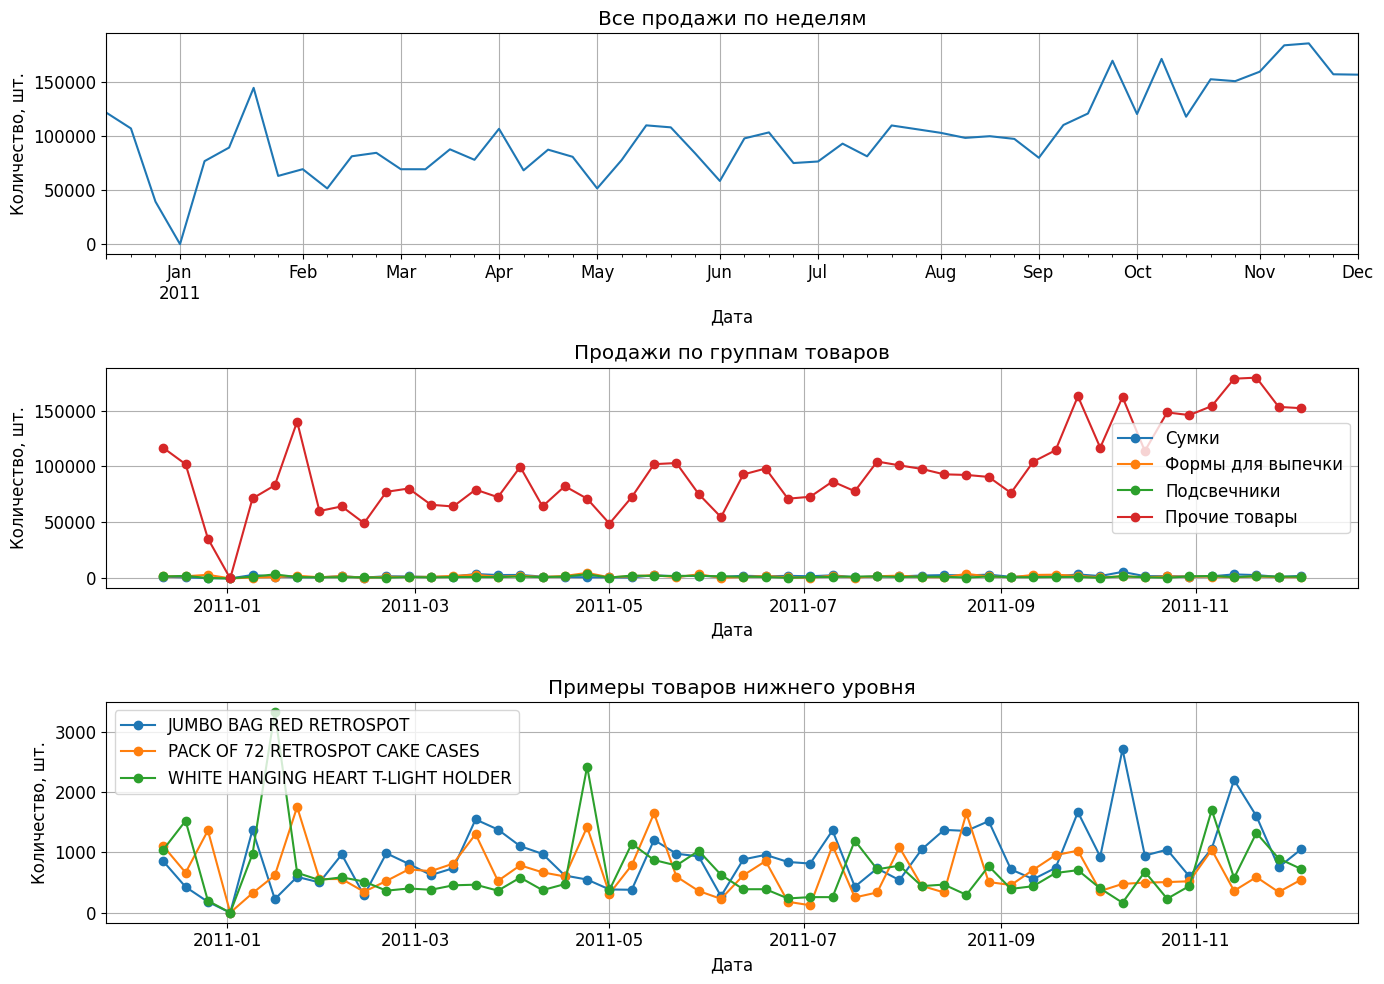

In [10]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

hierarchy_series["Всего"].plot(ax=axes[0], title="Все продажи по неделям")

for group in group_ids:
    axes[1].plot(
        hierarchy_series.index,
        hierarchy_series[group],
        marker="o",
        label=group
    )
axes[1].set_title("Продажи по группам товаров")
axes[1].legend()

example_products = [selected[group][0] for group in selected]
for code in example_products:
    axes[2].plot(
        hierarchy_series.index,
        hierarchy_series[code],
        marker="o",
        label=str(descriptions[code])
    )
axes[2].set_title("Примеры товаров нижнего уровня")
axes[2].legend()

for ax in axes:
    ax.set_xlabel("Дата")
    ax.set_ylabel("Количество, шт.")
    ax.grid(True)

plt.tight_layout()
plt.show()

ряды построены на одном недельном индексе, условие агрегации выполняется
для каждого периода. отобранные товары покрывают лишь 5,2% всех продаж,
основной объем приходится на узел Остальные товары - это фон,
на котором видны группы

в данных есть одна неделя без операций вообще - новогодняя, до 02.01.2011.
она занулена для всех узлов, как и остальные недели без записей

## модели

беру те же три модели, что в ДЗ 2:

- наивная - прогноз равен последнему значению обучающего ряда;
- Holt - экспоненциальное сглаживание с затухающим трендом, без сезонности;
- Gradient Boosting - бустинг по трем предыдущим значениям ряда,
  для нескольких шагов рекурсивный прогноз: предыдущие прогнозы
  становятся лагами следующих шагов

обучаю каждую модель отдельно на каждом узле иерархии.
отрицательные прогнозы продаж заменяю на 0

In [11]:
def make_lag_data(series, n_lags=3):
    values = series.to_numpy(dtype=float)
    features = []
    targets = []

    for i in range(n_lags, len(values)):
        features.append(values[i - n_lags:i][::-1])
        targets.append(values[i])

    return np.asarray(features), np.asarray(targets)


def forecast_naive(train, steps):
    return np.repeat(float(train.iloc[-1]), steps)


def forecast_holt(train, steps):
    model = ExponentialSmoothing(
        train,
        trend="add",
        damped_trend=True,
        initialization_method="estimated"
    )
    fitted = model.fit(optimized=True)
    forecast = fitted.forecast(steps)
    return np.maximum(forecast.to_numpy(dtype=float), 0)


def forecast_boosting(train, steps, n_lags=3):
    features, targets = make_lag_data(train, n_lags)
    model = GradientBoostingRegressor(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=2,
        random_state=42
    )
    model.fit(features, targets)

    history = train.to_numpy(dtype=float).tolist()
    predictions = []

    for _ in range(steps):
        last_values = np.array([
            history[-lag] for lag in range(1, n_lags + 1)
        ]).reshape(1, -1)
        prediction = max(float(model.predict(last_values)[0]), 0)
        predictions.append(prediction)
        history.append(prediction)

    return np.array(predictions)


def forecast_all(train, steps):
    return {
        "Наивная": forecast_naive(train, steps),
        "Holt": forecast_holt(train, steps),
        "Gradient Boosting": forecast_boosting(train, steps)
    }

## метрики

метрики те же, что в ДЗ 2:

- MAE - средняя ошибка в штуках;
- RMSE - тоже в штуках, но сильнее учитывает большие ошибки;
- WAPE - сумма абсолютных ошибок относительно суммы фактических продаж, в процентах;
- MASE - MAE относительно средней ошибки наивного прогноза по обучающим данным;
- ME - средняя ошибка со знаком, положительное значение значит завышение прогноза

MAPE не считаю: в рядах есть нулевые продажи, а при фактическом нуле
эта метрика не определена. между узлами разного масштаба сравниваю WAPE,
а не MAE: у группы Сумки и узла Остальные товары продажи отличаются на порядки

In [12]:
def calculate_metrics(actual, predicted, train):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    errors = predicted - actual
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    actual_sum = np.abs(actual).sum()
    wape = 100 * np.abs(errors).sum() / actual_sum if actual_sum != 0 else np.nan

    scale = np.abs(np.diff(train.to_numpy(dtype=float))).mean()
    mase = mae / scale if scale != 0 else np.nan

    return {
        "MAE": mae,
        "RMSE": rmse,
        "WAPE, %": wape,
        "MASE": mase,
        "ME (прогноз - факт)": errors.mean()
    }

## прогнозы до согласования

прогнозирую все узлы на 8 недель вперед и складываю результаты в единый
формат: строки - узлы, столбцы - шаги прогноза, отдельно для каждой модели.
так прогнозы всех узлов готовы к согласованию

потом проверю, сходятся ли независимые прогнозы в сумму: для каждого
родительского узла сравню его прогноз с суммой прогнозов дочерних

In [13]:
model_names = ["Наивная", "Holt", "Gradient Boosting"]

base_values = {name: {} for name in model_names}
for node in node_ids:
    train = train_series[node]
    forecasts = forecast_all(train, horizon)
    for name in model_names:
        base_values[name][node] = forecasts[name]

base_forecasts = {
    name: pd.DataFrame(values, index=range(1, horizon + 1)).T
    for name, values in base_values.items()
}

print("прогнозы построены для", len(node_ids), "узлов,", len(model_names), "моделей")
base_forecasts["Holt"].round(1)

прогнозы построены для 17 узлов, 3 моделей


,1,2,3,4,5,6,7,8
Всего,130877.0,134417.3,137939.8,141444.7,144932.1,148402.0,151854.6,155290.0
Сумки,2835.7,2871.2,2906.4,2941.5,2976.4,3011.1,3045.7,3080.1
Формы для выпечки,2002.3,2005.0,2007.6,2010.0,2012.3,2014.5,2016.6,2018.6
Подсвечники,1446.6,1446.6,1446.6,1446.6,1446.6,1446.6,1446.6,1446.6
Прочие товары,125172.4,128716.0,132241.9,135750.1,139240.8,142714.1,146170.0,149608.6
85099B,1206.2,1219.9,1233.6,1247.2,1260.8,1274.3,1287.7,1301.1
22386,666.3,677.2,688.0,698.7,709.4,720.1,730.7,741.2
20725,434.4,435.2,436.0,436.8,437.5,438.2,438.8,439.4
85099F,466.4,470.4,474.3,478.1,481.9,485.6,489.3,492.9
21212,676.0,676.0,676.0,676.0,676.0,676.0,676.0,676.0


In [14]:
def check_consistency(forecasts, children):
    rows = []
    for parent, childs in children.items():
        parent_forecast = forecasts.loc[parent]
        children_sum = forecasts.loc[childs].sum(axis=0)
        diff = parent_forecast - children_sum
        rows.append({
            "Узел": parent,
            "Среднее |расхождение|, шт.": np.abs(diff).mean(),
            "Максимальное |расхождение|, шт.": np.abs(diff).max()
        })
    return pd.DataFrame(rows)


for model_name in model_names:
    print(model_name)
    display(check_consistency(base_forecasts[model_name], children).round(2))

Наивная


,Узел,"Среднее |расхождение|, шт.","Максимальное |расхождение|, шт."
0,Сумки,0.0,0.0
1,Формы для выпечки,0.0,0.0
2,Подсвечники,0.0,0.0
3,Прочие товары,0.0,0.0
4,Всего,0.0,0.0


Holt


,Узел,"Среднее |расхождение|, шт.","Максимальное |расхождение|, шт."
0,Сумки,83.80,105.55
1,Формы для выпечки,19.90,27.78
2,Подсвечники,144.54,146.64
3,Прочие товары,0.00,0.00
4,Всего,722.99,863.86


Gradient Boosting


,Узел,"Среднее |расхождение|, шт.","Максимальное |расхождение|, шт."
0,Сумки,642.45,1083.77
1,Формы для выпечки,496.32,1122.71
2,Подсвечники,571.31,1417.72
3,Прочие товары,0.00,0.00
4,Всего,22763.57,57953.90


независимые прогнозы сходятся в сумму по-разному. наивная модель
согласована автоматически: последнее значение каждого ряда уже
удовлетворяет иерархии, поэтому расхождение нулевое. у Holt расхождения
умеренные (на общем уровне в среднем около 723 шт.), а у Gradient Boosting
самые большие (на общем уровне в среднем около 22,8 тыс. шт.)

чем сложнее модель, тем сильнее независимые прогнозы расходятся
с иерархией, и тем нужнее согласование. визуального сходства недостаточно

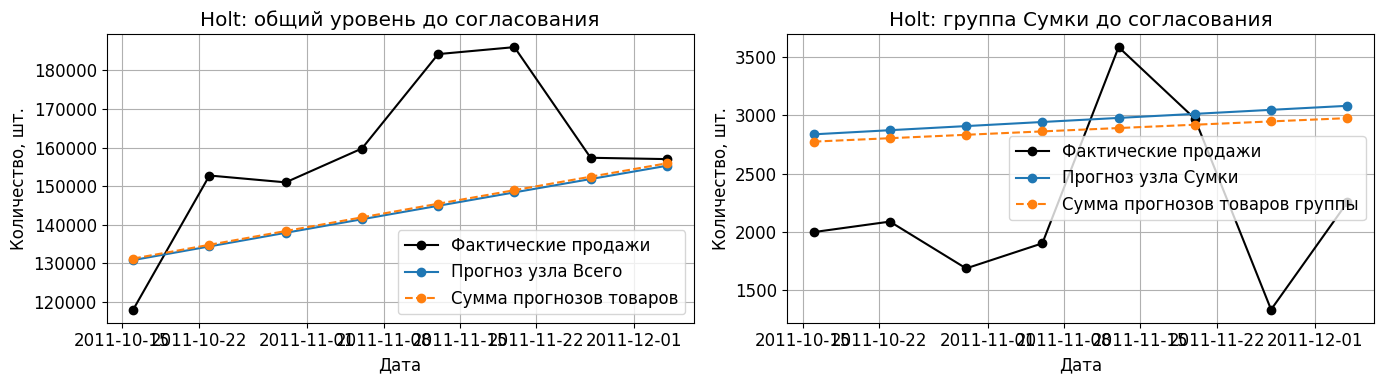

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

holt = base_forecasts["Holt"]
test_index = test_series.index

axes[0].plot(
    test_index, test_series["Всего"],
    marker="o", color="black", label="Фактические продажи"
)
axes[0].plot(
    test_index, holt.loc["Всего"],
    marker="o", label="Прогноз узла Всего"
)
axes[0].plot(
    test_index, holt.loc[bottom_ids].sum(axis=0),
    marker="o", linestyle="--", label="Сумма прогнозов товаров"
)
axes[0].set_title("Holt: общий уровень до согласования")
axes[0].set_xlabel("Дата")
axes[0].set_ylabel("Количество, шт.")
axes[0].legend()
axes[0].grid(True)

group = "Сумки"
axes[1].plot(
    test_index, test_series[group],
    marker="o", color="black", label="Фактические продажи"
)
axes[1].plot(
    test_index, holt.loc[group],
    marker="o", label=f"Прогноз узла {group}"
)
axes[1].plot(
    test_index, holt.loc[children[group]].sum(axis=0),
    marker="o", linestyle="--", label="Сумма прогнозов товаров группы"
)
axes[1].set_title(f"Holt: группа {group} до согласования")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество, шт.")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

## согласование прогнозов

согласование (reconciliation) пересчитывает прогнозы так, чтобы условия
иерархии выполнялись точно, а не только визуально

запишу иерархию матрицей суммирования S: строки - все узлы, столбцы -
нижний уровень. S[i, j] = 1, если товар j входит в узел i, иначе 0.
тогда любой согласованный набор прогнозов имеет вид S @ b,
где b - прогнозы нижнего уровня

реализую четыре подхода:

- Bottom-up: прогнозы товаров не меняются, родители собираются из них суммой;
- Top-down (прогнозные доли): прогноз узла Всего распределяется по узлам
  пропорционально собственным прогнозам товаров на каждом шаге;
  если сумма прогнозов товаров нулевая, беру исторические доли;
- Top-down (исторические доли): то же, но доли считаются по обучающим
  данным и одинаковы для всех шагов;
- MinT (OLS): согласование в смысле наименьших квадратов, поправляются
  все узлы сразу: y_rec = S @ (S'S)^(-1) @ S' @ y_hat

матрица S строится по структуре иерархии, исторические доли - только
по обучающим данным. отбор товаров тоже выполнен по обучающему периоду,
поэтому будущие продажи не используются при построении прогнозов
и расчёте долей. после согласования проверяю условие
родитель = сумма дочерних для всех моделей и методов

In [16]:
def build_summing_matrix(parent_of, bottom_ids, node_ids):
    S = np.zeros((len(node_ids), len(bottom_ids)))
    for j, bottom_id in enumerate(bottom_ids):
        node = bottom_id
        while node is not None:
            S[node_ids.index(node), j] = 1
            node = parent_of.get(node)
    return S


S = build_summing_matrix(parent_of, bottom_ids, node_ids)

S_df = pd.DataFrame(S, index=node_ids, columns=bottom_ids)
print("размер матрицы S:", S.shape)
S_df

размер матрицы S: (17, 12)


,85099B,22386,20725,85099F,21212,21977,84991,21213,85123A,22178,84755,Остальные товары
Всего,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0
Сумки,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
Формы для выпечки,0.0,0.0,0.0,0.0,1.0,1.0,1.0,1.0,0.0,0.0,0.0,0.0
Подсвечники,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
Прочие товары,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
85099B,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
22386,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
20725,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
85099F,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
21212,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
def reconcile_bottom_up(y_hat, S, train_shares):
    n_bottom = S.shape[1]
    return S @ y_hat[len(y_hat) - n_bottom:]


def reconcile_top_down_proportions(y_hat, S, train_shares):
    n_bottom = S.shape[1]
    bottom = y_hat[len(y_hat) - n_bottom:]
    total = bottom.sum()
    shares = bottom / total if total > 0 else train_shares
    return y_hat[0] * (S @ shares)


def reconcile_top_down_historical(y_hat, S, train_shares):
    return y_hat[0] * (S @ train_shares)


def reconcile_mint_ols(y_hat, S, train_shares):
    G = S @ np.linalg.pinv(S.T @ S) @ S.T
    return G @ y_hat


reconcile_methods = {
    "Bottom-up": reconcile_bottom_up,
    "Top-down (прогнозные доли)": reconcile_top_down_proportions,
    "Top-down (исторические доли)": reconcile_top_down_historical,
    "MinT (OLS)": reconcile_mint_ols
}

In [18]:
train_bottom = train_series[bottom_ids]
train_shares = (train_bottom.sum() / train_bottom.sum().sum()).to_numpy()

reconciled_forecasts = {}
for model_name in model_names:
    reconciled_forecasts[model_name] = {}
    forecasts = base_forecasts[model_name]
    for method_name, method in reconcile_methods.items():
        values = np.column_stack([
            method(forecasts[step].to_numpy(), S, train_shares)
            for step in forecasts.columns
        ])
        reconciled_forecasts[model_name][method_name] = pd.DataFrame(
            values, index=node_ids, columns=forecasts.columns
        )

print("согласованные прогнозы построены:", len(reconcile_methods), "методами")
reconciled_forecasts["Holt"]["Bottom-up"].round(1)

согласованные прогнозы построены: 4 методами


,1,2,3,4,5,6,7,8
Всего,131260.2,134838.7,138399.1,141941.5,145466.1,148972.9,152461.9,155933.4
Сумки,2773.2,2802.7,2832.0,2860.9,2889.7,2918.2,2946.5,2974.5
Формы для выпечки,2014.7,2019.4,2024.1,2028.7,2033.2,2037.6,2042.0,2046.4
Подсвечники,1299.9,1300.6,1301.2,1301.8,1302.4,1302.9,1303.4,1303.9
Прочие товары,125172.4,128716.0,132241.9,135750.1,139240.8,142714.1,146170.0,149608.6
85099B,1206.2,1219.9,1233.6,1247.2,1260.8,1274.3,1287.7,1301.1
22386,666.3,677.2,688.0,698.7,709.4,720.1,730.7,741.2
20725,434.4,435.2,436.0,436.8,437.5,438.2,438.8,439.4
85099F,466.4,470.4,474.3,478.1,481.9,485.6,489.3,492.9
21212,676.0,676.0,676.0,676.0,676.0,676.0,676.0,676.0


In [19]:
for model_name in model_names:
    for method_name, forecasts in reconciled_forecasts[model_name].items():
        for parent, childs in children.items():
            assert np.allclose(
                forecasts.loc[parent],
                forecasts.loc[childs].sum(axis=0)
            )

print("условие родитель = сумма дочерних выполняется для всех методов и моделей")

negative_counts = {}
for model_name in model_names:
    for method_name, forecasts in reconciled_forecasts[model_name].items():
        negative_counts[(model_name, method_name)] = int((forecasts < 0).sum().sum())

display(pd.Series(negative_counts, name="Отрицательных значений прогноза"))

условие родитель = сумма дочерних выполняется для всех методов и моделей


Наивная            Bottom-up                        0
                   Top-down (прогнозные доли)       0
                   Top-down (исторические доли)     0
                   MinT (OLS)                       0
Holt               Bottom-up                        0
                   Top-down (прогнозные доли)       0
                   Top-down (исторические доли)     0
                   MinT (OLS)                       0
Gradient Boosting  Bottom-up                        0
                   Top-down (прогнозные доли)       0
                   Top-down (исторические доли)     0
                   MinT (OLS)                      65
Name: Отрицательных значений прогноза, dtype: int64

## сравнение до и после

качество оцениваю на одном и том же тестовом отрезке из 8 недель
для всех вариантов: без согласования и после каждого метода.
метрики считаю для каждого узла, модели и горизонта 1, 4, 8 недель

сначала сводная таблица по уровням иерархии: средняя WAPE по узлам уровня.
потом подробные таблицы по узлам для модели Holt и горизонт 8 недель

In [20]:
variant_names = ["Без согласования"] + list(reconcile_methods.keys())
node_level = dict(zip(node_info["Узел"], node_info["Уровень"]))
level_names = {0: "Всего", 1: "Группы", 2: "Товары"}


def get_forecast(model_name, variant_name, node):
    if variant_name == "Без согласования":
        return base_forecasts[model_name].loc[node]
    return reconciled_forecasts[model_name][variant_name].loc[node]


rows = []
for model_name in model_names:
    for variant_name in variant_names:
        for node in node_ids:
            for h in horizons:
                actual = test_series[node].iloc[:h]
                predicted = get_forecast(model_name, variant_name, node).iloc[:h]
                metrics = calculate_metrics(actual, predicted, train_series[node])
                rows.append({
                    "Модель": model_name,
                    "Согласование": variant_name,
                    "Узел": node,
                    "Уровень": level_names[node_level[node]],
                    "Горизонт, шагов": h,
                    **metrics
                })

results = pd.DataFrame(rows)
print("строк с результатами:", len(results))
assert len(results) == len(model_names) * len(variant_names) * len(node_ids) * len(horizons)

строк с результатами: 765


In [21]:
summary = (
    results[results["Горизонт, шагов"] == horizon]
    .groupby(["Модель", "Уровень", "Согласование"], as_index=False)
    .agg({"WAPE, %": "mean", "MASE": "mean"})
    .rename(columns={"WAPE, %": "Средняя WAPE, %", "MASE": "Средняя MASE"})
)

display(summary.round(3))

,Модель,Уровень,Согласование,"Средняя WAPE, %",Средняя MASE
0,Gradient Boosting,Всего,Bottom-up,32.678,2.147
1,Gradient Boosting,Всего,MinT (OLS),40.474,2.659
2,Gradient Boosting,Всего,Top-down (исторические доли),43.216,2.839
3,Gradient Boosting,Всего,Top-down (прогнозные доли),43.216,2.839
4,Gradient Boosting,Всего,Без согласования,43.216,2.839
5,Gradient Boosting,Группы,Bottom-up,44.096,1.301
6,Gradient Boosting,Группы,MinT (OLS),214.686,4.393
7,Gradient Boosting,Группы,Top-down (исторические доли),33.644,1.187
8,Gradient Boosting,Группы,Top-down (прогнозные доли),46.356,1.443
9,Gradient Boosting,Группы,Без согласования,43.304,1.242


In [22]:
node_results = results[
    (results["Модель"] == "Holt")
    & (results["Горизонт, шагов"] == horizon)
]

print("Holt, горизонт 8 недель: MAE по узлам, шт.")
display(node_results.pivot(index="Узел", columns="Согласование", values="MAE").round(2))

print("Holt, горизонт 8 недель: WAPE по узлам, %")
display(node_results.pivot(index="Узел", columns="Согласование", values="WAPE, %").round(1))

Holt, горизонт 8 недель: MAE по узлам, шт.


Согласование,Bottom-up,MinT (OLS),Top-down (исторические доли),Top-down (прогнозные доли),Без согласования
Узел,,,,,
20725,125.65,120.78,189.51,125.24,125.65
21212,216.39,186.83,554.03,214.58,216.39
21213,204.55,178.52,252.42,203.42,204.55
21977,333.15,294.15,549.87,331.08,333.15
22178,247.08,244.61,346.72,246.25,247.08
22386,273.46,259.46,224.12,271.51,273.46
84755,132.58,130.83,364.34,132.14,132.58
84991,161.54,160.87,235.73,161.18,161.54
85099B,413.08,404.40,459.89,410.98,413.08


Holt, горизонт 8 недель: WAPE по узлам, %


Согласование,Bottom-up,MinT (OLS),Top-down (исторические доли),Top-down (прогнозные доли),Без согласования
Узел,,,,,
20725,31.7,30.5,47.8,31.6,31.7
21212,39.3,33.9,100.5,38.9,39.3
21213,88.6,77.4,109.4,88.2,88.6
21977,133.7,118.1,220.7,132.9,133.7
22178,49.6,49.1,69.6,49.4,49.6
22386,61.6,58.4,50.4,61.1,61.6
84755,78.9,77.9,216.9,78.7,78.9
84991,45.1,44.9,65.8,45.0,45.1
85099B,35.7,34.9,39.7,35.5,35.7


In [23]:
total_results = results[results["Узел"] == "Всего"]

print("узел Всего: MAE по горизонтам, шт.")
display(
    total_results.pivot_table(
        index=["Модель", "Горизонт, шагов"],
        columns="Согласование",
        values="MAE"
    ).round(2)
)

узел Всего: MAE по горизонтам, шт.


Согласование                       Bottom-up  MinT (OLS)  \
Модель            Горизонт, шагов                          
Gradient Boosting 1                  5449.02    16754.42   
                  4                 16371.10    42707.17   
                  8                 51719.29    64058.05   
Holt              1                 13199.23    12954.53   
                  4                 15385.21    15548.73   
                  8                 17909.95    18188.24   
Наивная           1                 53565.00    53565.00   
                  4                 26230.50    26230.50   
                  8                 20092.88    20092.88   

Согласование                       Top-down (исторические доли)  \
Модель            Горизонт, шагов                                 
Gradient Boosting 1                                    20849.16   
                  4                                    51918.52   
                  8                                    68397.55   
Holt              1                                    12816.03   
                  4                                    15633.83   
                  8                                    18328.70   
Наивная           1                                    53565.00   
                  4                                    26230.50   
                  8                                    20092.88   

Согласование                       Top-down (прогнозные доли)  \
Модель            Горизонт, шагов                               
Gradient Boosting 1                                  20849.16   
                  4                                  51918.52   
                  8                                  68397.55   
Holt              1                                  12816.03   
                  4                                  15633.83   
                  8                                  18328.70   
Наивная           1                                  53565.00   
                  4                                  26230.50   
                  8                                  20092.88   

Согласование                       Без согласования  
Модель            Горизонт, шагов                    
Gradient Boosting 1                        20849.16  
                  4                        51918.52  
                  8                        68397.55  
Holt              1                        12816.03  
                  4                        15633.83  
                  8                        18328.70  
Наивная           1                        53565.00  
                  4                        26230.50  
                  8                        20092.88

сравнение на одном тестовом отрезке, горизонт 8 недель:

- наивная модель уже согласована, поэтому Bottom-up, MinT и Top-down
  (прогнозные доли) ничего не меняют. Top-down (исторические доли) немного
  меняет распределение, потому что перераспределяет прогноз по историческим
  долям, а не по собственным прогнозам узлов;
- для Holt на общем уровне согласование меняет мало (WAPE около 11,3-11,6%).
  на уровне групп и товаров лучше всего MinT (OLS): WAPE 28,5% и 57,2%
  против 31,0% и 61,0% без согласования, и по MASE он тоже лучший;
- для Gradient Boosting эффект сильный и неоднозначный. Bottom-up улучшает
  общий уровень (WAPE 43,2% -> 32,7%): сумма прогнозов товаров точнее
  прямого прогноза итога. но MinT (OLS) на уровнях групп и товаров дает
  огромные ошибки (WAPE 215% и 337%) и 65 отрицательных прогнозов;
- Top-down (исторические доли) для Holt заметно хуже (WAPE товаров 94,2%
  против 61,0%): исторические доли не совпадают с долями тестового периода.
  для Gradient Boosting на уровнях групп и товаров он, наоборот, лучший;
- средняя WAPE по уровню Товары включает крупный агрегат Остальные товары
  (WAPE около 12%), поэтому это не средняя только по 11 отобранным товарам

согласование гарантирует математическую согласованность, но не гарантирует
рост точности. эффект зависит от базовой модели и метода

## графики

графики прогнозов для модели Holt: общий уровень и группа Сумки,
потом примеры товаров нижнего уровня. серый пунктир - граница теста,
черная линия - фактические продажи тестового периода

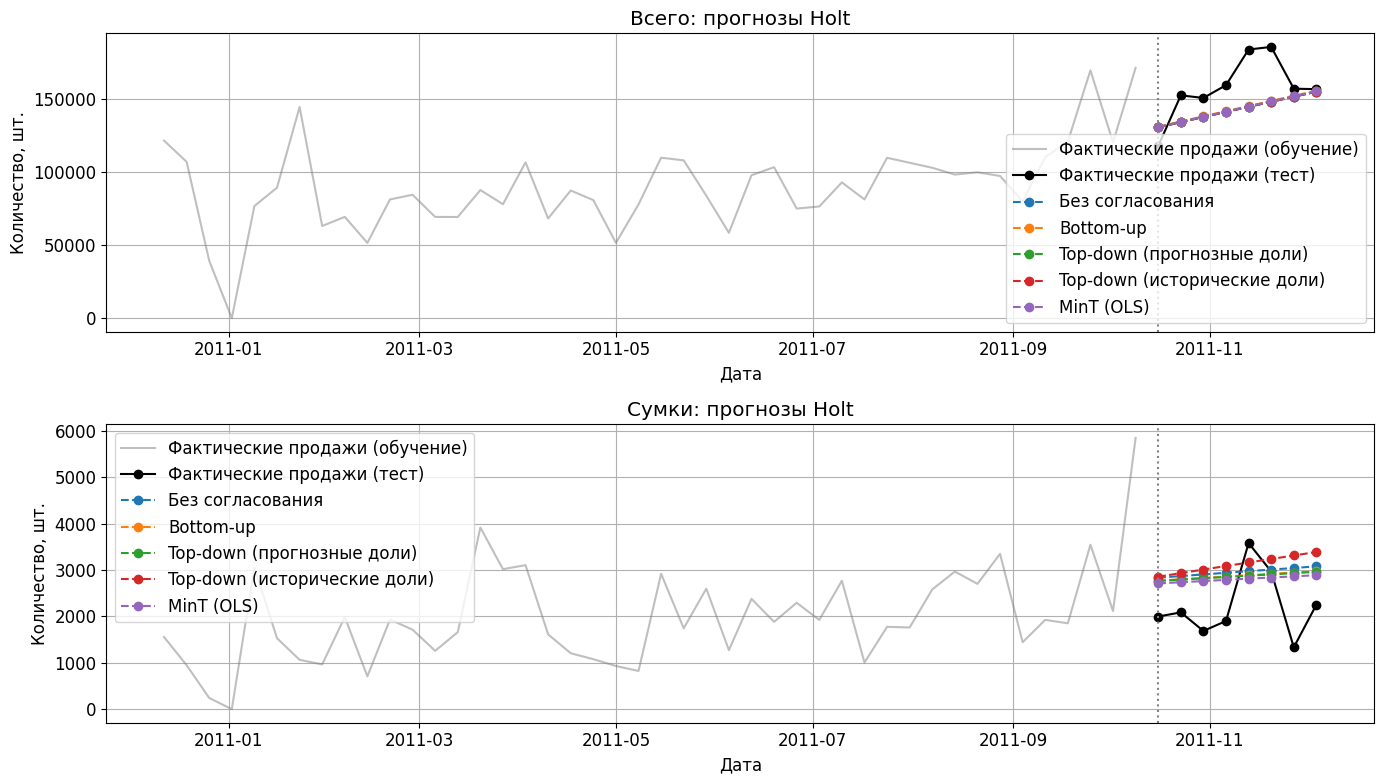

In [24]:
def plot_node_forecasts(node, model_name, ax):
    train = train_series[node]
    test = test_series[node]

    ax.plot(
        train.index, train.values,
        color="gray", alpha=0.5, label="Фактические продажи (обучение)"
    )
    ax.plot(
        test.index, test.values,
        marker="o", color="black", label="Фактические продажи (тест)"
    )
    ax.plot(
        test.index, base_forecasts[model_name].loc[node],
        marker="o", linestyle="--", label="Без согласования"
    )
    for method_name in reconcile_methods:
        ax.plot(
            test.index,
            reconciled_forecasts[model_name][method_name].loc[node],
            marker="o", linestyle="--", label=method_name
        )

    ax.axvline(test.index[0], color="gray", linestyle=":")
    ax.set_title(f"{node}: прогнозы {model_name}")
    ax.set_xlabel("Дата")
    ax.set_ylabel("Количество, шт.")
    ax.legend()
    ax.grid(True)


fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_node_forecasts("Всего", "Holt", axes[0])
plot_node_forecasts("Сумки", "Holt", axes[1])
plt.tight_layout()
plt.show()

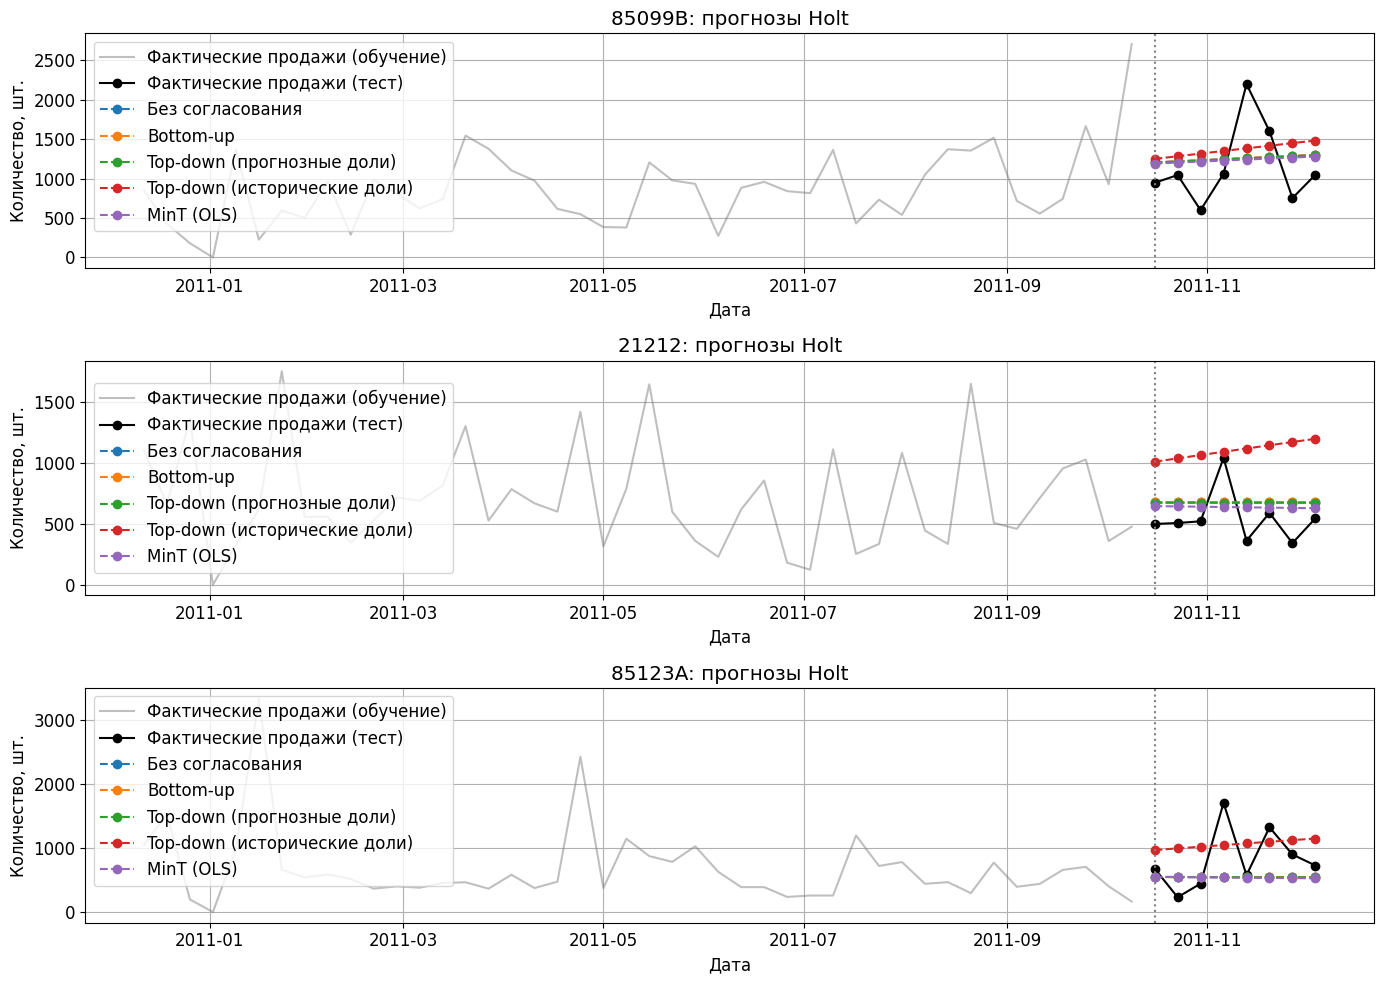

In [25]:
fig, axes = plt.subplots(3, 1, figsize=(14, 10))
for ax, code in zip(axes, example_products):
    plot_node_forecasts(code, "Holt", ax)
plt.tight_layout()
plt.show()

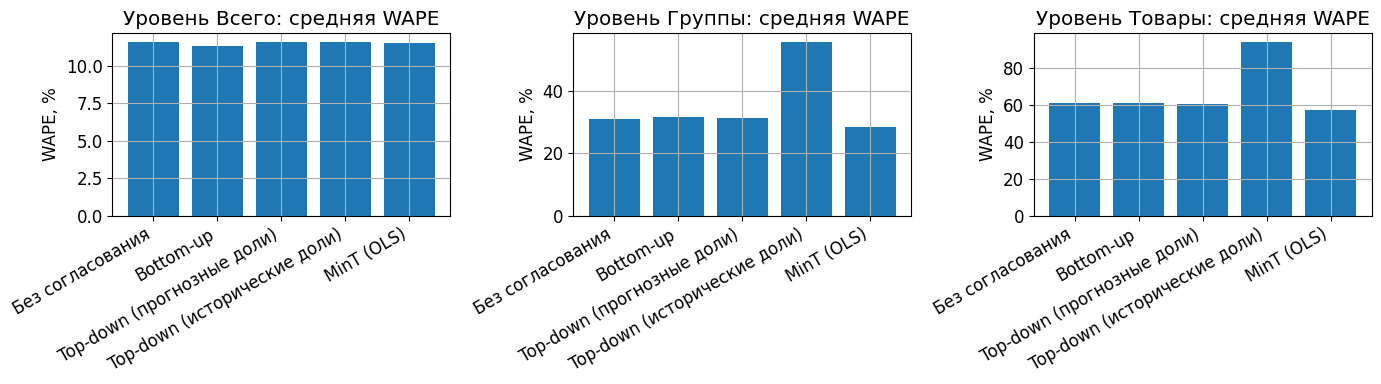

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

holt_results = results[
    (results["Модель"] == "Holt")
    & (results["Горизонт, шагов"] == horizon)
]

for ax, level in zip(axes, ["Всего", "Группы", "Товары"]):
    part = (
        holt_results[holt_results["Уровень"] == level]
        .groupby("Согласование", as_index=False)["WAPE, %"].mean()
        .set_index("Согласование")
        .reindex(variant_names)
    )
    ax.bar(range(len(part)), part["WAPE, %"])
    ax.set_xticks(range(len(part)))
    ax.set_xticklabels(variant_names, rotation=30, ha="right")
    ax.set_title(f"Уровень {level}: средняя WAPE")
    ax.set_ylabel("WAPE, %")
    ax.grid(True)

plt.tight_layout()
plt.show()

## выводы

- построила иерархию из 17 узлов: общий уровень, 4 группы и 12 нижних узлов
  (11 товаров + Остальные товары). связи родитель-потомок однозначные,
  условие агрегации проверено для каждой недели;
- отобранные товары покрывают 5,2% продаж, основной объем - в узле
  Остальные товары. частота единая (W-SUN), горизонты 1, 4, 8 недель,
  тест один и тот же для всех вариантов;
- товары отобраны по итогам обучающего периода, поэтому будущие продажи
  не влияют на структуру иерархии. матрица S и исторические доли тоже
  построены без использования теста;
- независимые прогнозы не всегда согласованы: наивная модель согласована
  автоматически, Holt расходится умеренно, Gradient Boosting сильно.
  после согласования условие родитель = сумма дочерних выполняется точно
  для всех методов и моделей;
- согласование не гарантирует рост точности. для Holt лучшие результаты
  на уровне групп и товаров дает MinT (OLS) и по WAPE, и по MASE.
  для Gradient Boosting общий уровень улучшает Bottom-up
  (WAPE 43,2% -> 32,7%), а на уровнях групп и товаров - Top-down
  (исторические доли);
- MinT (OLS) не ограничивает прогнозы снизу нулем: для Gradient Boosting
  получилось 65 отрицательных значений и огромные WAPE на уровнях групп
  и товаров. это ограничение метода в такой постановке;
- Top-down (исторические доли) для Holt хуже, потому что исторические доли
  не совпадают с долями тестового периода;
- результаты получены на одном тестовом отрезке из 8 недель, поэтому могут
  измениться при другом разделении. сравнение проведено на одинаковом
  тестовом периоде